# Machine learning labs · Check your setup

Run this notebook in local Jupyter, MIN JupyterHub, Google Colab, or the course
Nix environment. It is self-contained: **no lab folder or helper file is needed**.
We use **PyTorch on the CPU** and Matplotlib for plotting. NumPy is installed
as an environment dependency; no NumPy or PyTorch experience is assumed.

In a Git checkout, copy this notebook from `setup` into the ignored `my-work`
folder before running it. Create that folder at the course root if necessary.
In Colab, upload this notebook alone.

Run cells in order with **Shift+Enter**. All code is supplied: there are no
exercises to complete here. Check that the plot appears, save your copy, and
reopen it. This notebook installs and downloads nothing.

## 1. Check the installed libraries

The first cell imports the libraries, reports their versions, and checks the
course requirements: Python **3.10+**, NumPy **1.24+**, Matplotlib **3.7+**, and
PyTorch **2.2+ within version 2**. You do not need to understand this check's
implementation. If it fails, follow the setup instructions for your route,
restart the kernel/runtime, and rerun this notebook.

In [6]:
import sys
import re
import numpy
import matplotlib
import matplotlib.pyplot as plt
import torch

print("Python:", sys.version.split()[0])
print("Python executable:", sys.executable)
assert sys.version_info[:2] >= (3, 10), "Select Python 3.10 or newer."

for name, version, minimum in (
    ("NumPy", numpy.__version__, (1, 24)),
    ("Matplotlib", matplotlib.__version__, (3, 7)),
    ("PyTorch", torch.__version__, (2, 2)),
):
    print(name + ":", version)
    major_minor = tuple(map(int, re.match(r"(\d+)\.(\d+)", version).groups()))
    assert major_minor >= minimum, f"Update {name} using your setup guide."
    if name == "PyTorch":
        assert major_minor[0] == 2, "Select PyTorch 2.x for this course."

print("Installed libraries: OK")
environment_ok = True

Python: 3.13.15
Python executable: /nix/store/l7503j63fq8ap6k7ni13gazm6b29sagq-python3-3.13.15-env/bin/python3.13
NumPy: 2.4.4
Matplotlib: 3.10.9
PyTorch: 2.11.0
Installed libraries: OK


## 2. A small PyTorch calculation on the CPU

A **tensor** stores numbers. This example uses three inputs in a column,
applies the positive part `torch.relu`, makes predictions, and calculates
the mean squared error. We will learn these operations in Lab 1.

You should see an input shape of `torch.Size([3, 1])`, three predictions,
and a mean squared error of approximately `0.667`.

In [7]:
x = torch.tensor([[-1.0], [0.0], [2.0]], device="cpu")
y = torch.tensor([[-0.5], [0.5], [2.5]], device="cpu")
prediction = 2 * torch.relu(x) - 0.5
loss = ((prediction - y)**2).mean()

print("Input shape:", x.shape)
print("Predictions:\n", prediction)
print("Mean squared error:", loss.item())
assert x.device.type == "cpu"
assert prediction.shape == y.shape == (3, 1)
torch.testing.assert_close(prediction, torch.tensor([[-0.5], [-0.5], [3.5]]))
torch.testing.assert_close(loss, torch.tensor(2 / 3))
print("PyTorch CPU calculation: OK")
torch_cpu_ok = True

Input shape: torch.Size([3, 1])
Predictions:
 tensor([[-0.5000],
        [-0.5000],
        [ 3.5000]])
Mean squared error: 0.6666666865348816
PyTorch CPU calculation: OK


## 3. Check that plots appear

Run the supplied plotting code. You should see the parabola $y=x^2$.

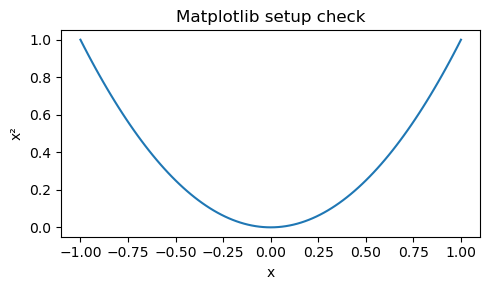

Plotting calls: OK. Check that the plot is visible above.


In [8]:
grid = torch.linspace(-1, 1, 101, device="cpu")
plt.figure(figsize=(5, 3))
plt.plot(grid, grid**2)
plt.xlabel("x")
plt.ylabel("x²")
plt.title("Matplotlib setup check")
plt.tight_layout()
plt.show()
print("Plotting calls: OK. Check that the plot is visible above.")
plot_ok = True

In [9]:
assert environment_ok and torch_cpu_ok and plot_ok
print("SETUP SUCCESS: all required setup checks passed.")
print("If the plot is visible and you can save your notebook, you are ready for Lab 1.")
print("All compulsory work uses the CPU. No CUDA installation is needed.")

SETUP SUCCESS: all required setup checks passed.
If the plot is visible and you can save your notebook, you are ready for Lab 1.
All compulsory work uses the CPU. No CUDA installation is needed.


## Optional: GPU information

This cell only reports whether PyTorch can see a CUDA GPU. It does not run
GPU computations. **`CUDA available: False` is fine for Lab 1.** The supplied
Nix environment is CPU-only; a working hosted PyTorch installation may also
support GPUs. You do not need to change either environment.

In [10]:
print("CUDA available:", torch.cuda.is_available())
print("Continue using the CPU for Lab 1.")

CUDA available: False
Continue using the CPU for Lab 1.


Save your notebook before closing the session. For a clean check, restart
the kernel/runtime and run all cells. If a required check failed, include
your chosen route, the first error, and the reported versions when asking
for help. The setup guide explains how to select or repair your environment.